In [1]:
import pandas as pd 

# Data Load Krna

df=pd.read_csv(r"C:\Users\pk\OneDrive\Desktop\comp.csv")
print(df.head)

<bound method NDFrame.head of     experience_years education_level           job_role company_size location  \
0                  1       Bachelors       Data Analyst        Small      USA   
1                  2         Masters       Data Analyst       Medium      USA   
2                  3         Masters     Data Scientist        Large      USA   
3                  5             PhD     Data Scientist        Large      USA   
4                  7             PhD        ML Engineer        Large      USA   
5                  2       Bachelors  Software Engineer       Medium   Canada   
6                  4         Masters  Software Engineer        Large   Canada   
7                  6         Masters        ML Engineer        Large       UK   
8                  3       Bachelors       Data Analyst        Small       UK   
9                  8             PhD     Data Scientist        Large  Germany   
10                10             PhD        ML Engineer        Large  Germany  

In [2]:
# Encoding krna computer understand binary

from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

df['education_level_encode']=le.fit_transform(df[['education_level']])
df['job_role_encode']=le.fit_transform(df[['job_role']])
df['company_size_encode']=le.fit_transform(df[['company_size']])
df['location_encode']=le.fit_transform(df[['location']])

# Drop the Categorial Data
df.drop(['education_level','job_role','company_size','location'],axis='columns',inplace=True)

print(df)

# Bachelors=0  Master=1  Phd=2                                                            education level
# Data analyst=0  data scientist=1  ml engineer=2  software engineer=3                    job role
# usa=4  canada=0   uk=3  germany=1  india=2                                              location
# small=2  medium=1 large=0                                                               company size



    experience_years  salary  education_level_encode  job_role_encode  \
0                  1   45000                       0                0   
1                  2   55000                       1                0   
2                  3   75000                       1                1   
3                  5  120000                       2                1   
4                  7  150000                       2                2   
5                  2   60000                       0                3   
6                  4   85000                       1                3   
7                  6  130000                       1                2   
8                  3   50000                       0                0   
9                  8  140000                       2                1   
10                10  170000                       2                2   
11                 1   30000                       0                3   
12                 2   40000                       

C:\Users\pk\AppData\Roaming\Python\Python310\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\pk\AppData\Roaming\Python\Python310\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\pk\AppData\Roaming\Python\Python310\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\pk\AppData\Roaming\Python\Python310\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was pass

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X=df[['experience_years','education_level_encode','job_role_encode','company_size_encode','location_encode']]
y=df['salary']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model=LinearRegression()
model.fit(X,y)
model.predict([[7,2,2,0,2]])[0]

C:\Users\pk\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


132781.86361439072

In [4]:

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np




In [5]:
#  Model Train
model = LinearRegression()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.8488578396183435
MAE: 17155.27020282226
RMSE: 18935.22620863138


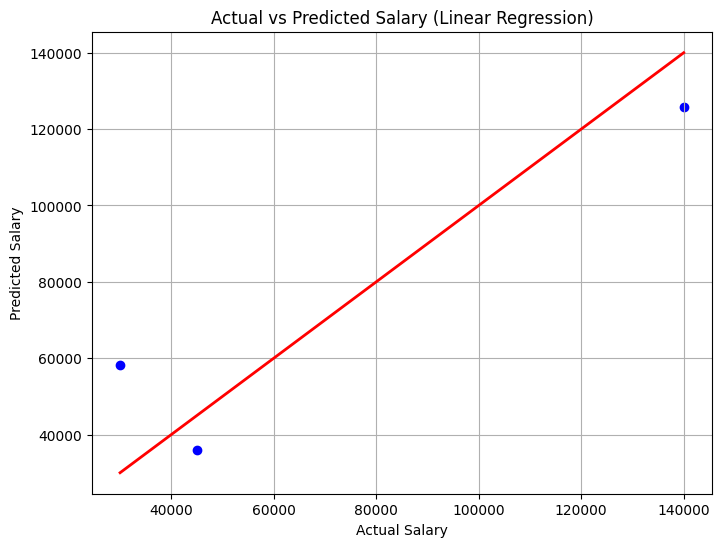

In [6]:
import matplotlib.pyplot as plt

# Actual vs Predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary (Linear Regression)")
plt.grid(True)
plt.show()

In [7]:
import joblib
joblib.dump(model,'Forescating_model.pkl')


['Forescating_model.pkl']